# Disrupted Threshold: Trading Precision for Recall
Follow-up to the five `03_2_baseline_model_tuning_*` notebooks and `03_3_confusion_matrices.ipynb`.

**The problem:** each tuned model's Disrupted threshold (about 0.79 to 0.85) was chosen to maximize **macro-F1**. At those thresholds the models catch only about 40% of real disruptions. For a disruption early-warning model, a missed disruption usually costs more than a false alarm, so this notebook tests **lower thresholds** that favor **recall**.

**Goal:** find a threshold that catches **at least 60% of real disruptions** (Disrupted recall >= 0.60) and see how much precision that costs.

**Nothing is retrained here.** Like 03_3, everything comes from the saved **out-of-fold** probabilities in `results/tuning/<model>/`: each training row was predicted by a model that never saw it. **The test set is still not used.**

Steps:
1. Load the saved probabilities and the shared setup
2. Sweep the threshold and score every value
3. Zoom in on the 0.50 to 0.70 range
4. Precision and recall curves
5. Pick each model's threshold for 60% recall, and check it holds on unseen folds
6. What the new threshold costs in false alarms
7. Takeaways

## 1. Load Results & Shared Setup
Same loading as `03_3_confusion_matrices.ipynb`: the tuned models' out-of-fold probabilities, checked to be in the same row order as the training data. The **current threshold** of each model is read from its `best_params.json`.

In [1]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import f1_score, fbeta_score

from tuning_setup import (DISRUPTED, STATUS_ORDER, load_training_data, make_folds, predict_with_threshold)

RECALL_TARGET = 0.60                                      # catch at least 60% of real disruptions
SWEEP_THRESHOLDS = np.round(np.arange(0.30, 0.901, 0.01), 2)
ZOOM_THRESHOLDS = [0.50, 0.55, 0.60, 0.65, 0.70]          # the range the team suggested

train_df, X_train, y_train = load_training_data()
y_train = y_train.to_numpy()
folds = make_folds(X_train, y_train)

# Display name -> results folder name
models = {
    "Logistic Regression": "logistic_regression",
    "Random Forest": "random_forest",
    "LightGBM": "lightgbm",
    "XGBoost": "xgboost",
    "CatBoost": "catboost",
}

def load_probabilities(folder):
    """Saved out-of-fold probabilities for one tuned model, checked against the training-data row order."""
    saved_df = pd.read_csv(f"../results/tuning/{folder}/out_of_fold_probabilities.csv")
    same_dates = (pd.to_datetime(saved_df["date"], format="%m/%d/%Y").to_numpy() == train_df["date"].to_numpy()).all()
    same_routes = (saved_df["route_id"].to_numpy() == train_df["route_id"].to_numpy()).all()
    assert same_dates and same_routes, f"{folder}: rows are not in the training-data order"
    return saved_df[[f"prob_{status.lower()}" for status in STATUS_ORDER]].to_numpy()

probabilities = {name: load_probabilities(folder) for name, folder in models.items()}

current_threshold = {}
for name, folder in models.items():
    with open(f"../results/tuning/{folder}/best_params.json") as f:
        current_threshold[name] = json.load(f)["disrupted_threshold"]

print("Training rows:", len(y_train), "| real disruptions:", int((y_train == DISRUPTED).sum()))
print("Current thresholds (chosen for macro-F1):", current_threshold)

Training rows: 25040 | real disruptions: 799
Current thresholds (chosen for macro-F1): {'Logistic Regression': 0.85, 'Random Forest': 0.82, 'LightGBM': 0.81, 'XGBoost': 0.8, 'CatBoost': 0.79}


## 2. Sweep the Threshold
The prediction rule is the one the tuning notebooks use (`predict_with_threshold`): a row is **Disrupted** if its Disrupted probability is at least the threshold, otherwise it gets the more likely of Normal and Delayed.

For every threshold from 0.30 to 0.90 (step 0.01) and every model:

| Score | Meaning |
|---|---|
| **Disrupted recall** | Of the real disruptions, the share the model flagged. *Our target: >= 0.60* |
| **Disrupted precision** | Of the rows flagged as Disrupted, the share that really were |
| **F1 / F2 (Disrupted)** | Recall and precision combined. F1 weighs them equally, **F2 counts recall as twice as important** |
| **macro-F1** | The overall score the current thresholds were chosen for |
| **flagged** | How many rows get a Disrupted alert |

In [2]:
def score_threshold(y, model_probabilities, threshold):
    """Disrupted-focused scores for one model at one threshold."""
    predictions = predict_with_threshold(model_probabilities, threshold)
    real, flagged = y == DISRUPTED, predictions == DISRUPTED
    caught = int((real & flagged).sum())
    return {
        "disrupted_recall": caught / real.sum(),
        "disrupted_precision": caught / flagged.sum() if flagged.sum() else 0.0,
        "f1_disrupted": f1_score(real, flagged, zero_division=0),
        "f2_disrupted": fbeta_score(real, flagged, beta=2, zero_division=0),
        "macro_f1": f1_score(y, predictions, average="macro"),
        "flagged": int(flagged.sum()),
        "caught": caught,
        "missed": int(real.sum()) - caught,
        "false_alarms": int(flagged.sum()) - caught,
    }

sweep_df = pd.DataFrame([{"model": name, "threshold": threshold, **score_threshold(y_train, probabilities[name], threshold)}
                         for name in models for threshold in SWEEP_THRESHOLDS])

# Where every model stands today
current_df = pd.DataFrame([{"model": name, "threshold": current_threshold[name],
                            **score_threshold(y_train, probabilities[name], current_threshold[name])}
                           for name in models]).set_index("model")
current_df[["threshold", "disrupted_recall", "disrupted_precision", "f1_disrupted", "macro_f1", "flagged"]].round(3)

,threshold,disrupted_recall,disrupted_precision,f1_disrupted,macro_f1,flagged
model,,,,,,
Logistic Regression,0.85,0.364,0.340,0.352,0.604,855
Random Forest,0.82,0.359,0.330,0.344,0.602,869
LightGBM,0.81,0.389,0.347,0.367,0.608,897
XGBoost,0.80,0.384,0.357,0.370,0.610,860
CatBoost,0.79,0.419,0.340,0.375,0.611,986


**Today:** every model catches well under half of the real disruptions (the `disrupted_recall` column above). That is the gap this notebook tries to close.

## 3. The 0.50 to 0.70 Range
Recall and precision at the thresholds the team suggested, one row per threshold and one column per model.

In [3]:
zoom_df = sweep_df[sweep_df["threshold"].isin(ZOOM_THRESHOLDS)]

print("Disrupted RECALL (target: at least", RECALL_TARGET, ")")
display(zoom_df.pivot(index="threshold", columns="model", values="disrupted_recall")[list(models)].round(3))

print("Disrupted PRECISION")
display(zoom_df.pivot(index="threshold", columns="model", values="disrupted_precision")[list(models)].round(3))

print("macro-F1")
display(zoom_df.pivot(index="threshold", columns="model", values="macro_f1")[list(models)].round(3))

Disrupted RECALL (target: at least 0.6 )


model,Logistic Regression,Random Forest,LightGBM,XGBoost,CatBoost
threshold,,,,,
0.50,0.776,0.758,0.717,0.695,0.701
0.55,0.735,0.715,0.690,0.657,0.668
0.60,0.693,0.666,0.646,0.625,0.631
0.65,0.657,0.607,0.607,0.578,0.576
0.70,0.606,0.549,0.547,0.511,0.528


Disrupted PRECISION


model,Logistic Regression,Random Forest,LightGBM,XGBoost,CatBoost
threshold,,,,,
0.50,0.155,0.158,0.174,0.181,0.176
0.55,0.169,0.171,0.191,0.197,0.194
0.60,0.184,0.187,0.208,0.220,0.213
0.65,0.207,0.206,0.231,0.248,0.231
0.70,0.233,0.229,0.256,0.266,0.257


macro-F1


model,Logistic Regression,Random Forest,LightGBM,XGBoost,CatBoost
threshold,,,,,
0.50,0.534,0.540,0.551,0.557,0.554
0.55,0.547,0.551,0.563,0.568,0.565
0.60,0.559,0.563,0.573,0.580,0.577
0.65,0.573,0.574,0.584,0.592,0.584
0.70,0.586,0.585,0.594,0.597,0.594


## 4. Precision and Recall Curves
One panel per model. Lowering the threshold (moving left) raises recall and lowers precision.
- The **shaded band** is the 0.50 to 0.70 range.
- The **dashed horizontal line** is the 60% recall target.
- The **dotted vertical line** is the model's current threshold.

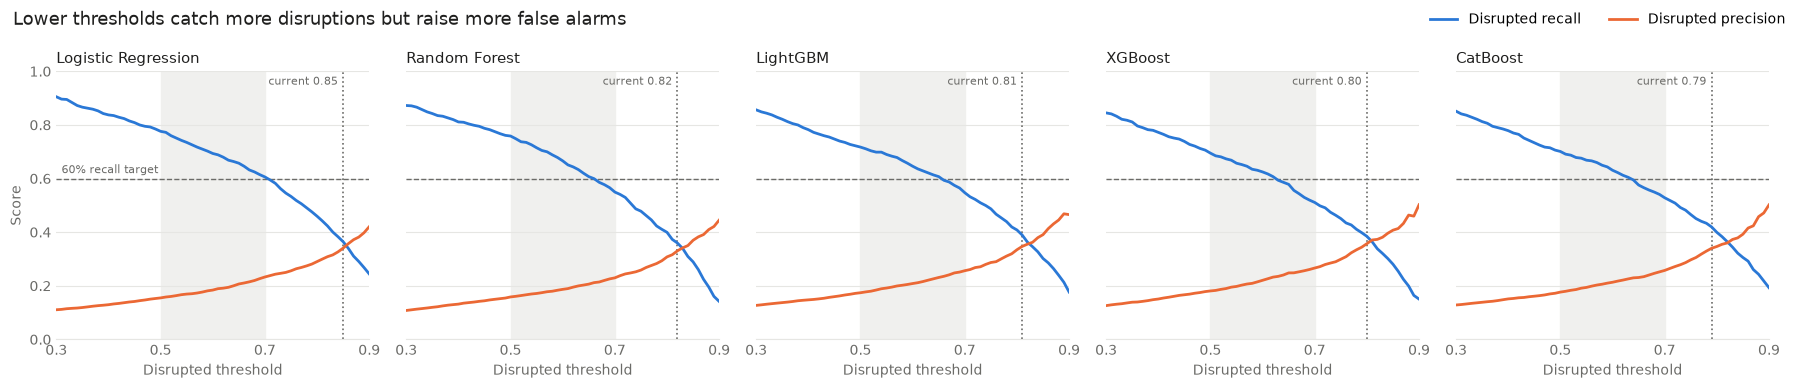

In [4]:
RECALL_COLOR, PRECISION_COLOR = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#1f1f1e", "#6b6b68", "#e6e6e3"

fig, axes = plt.subplots(1, len(models), figsize=(18, 3.9), sharey=True)
for ax, name in zip(axes, models):
    model_df = sweep_df[sweep_df["model"] == name]
    ax.axvspan(0.50, 0.70, color="#f0f0ee", zorder=0)
    ax.axhline(RECALL_TARGET, color=MUTED, linestyle="--", linewidth=1)
    ax.axvline(current_threshold[name], color=MUTED, linestyle=":", linewidth=1.2)
    ax.plot(model_df["threshold"], model_df["disrupted_recall"], color=RECALL_COLOR, linewidth=2, label="Disrupted recall")
    ax.plot(model_df["threshold"], model_df["disrupted_precision"], color=PRECISION_COLOR, linewidth=2, label="Disrupted precision")

    ax.set_title(name, fontsize=11, color=INK, loc="left")
    ax.set_xlabel("Disrupted threshold", color=MUTED)
    ax.set_xlim(0.30, 0.90)
    ax.set_ylim(0, 1)
    ax.set_xticks([0.3, 0.5, 0.7, 0.9])
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.tick_params(colors=MUTED, length=0)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.text(current_threshold[name] - 0.01, 0.95, f"current {current_threshold[name]:.2f}", color=MUTED, fontsize=8, ha="right")

axes[0].set_ylabel("Score", color=MUTED)
axes[0].text(0.31, RECALL_TARGET + 0.02, "60% recall target", color=MUTED, fontsize=8)
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncol=2, frameon=False, fontsize=10)
fig.suptitle("Lower thresholds catch more disruptions but raise more false alarms", x=0.01, ha="left", fontsize=13, color=INK)
plt.tight_layout()
plt.show()

## 5. The Threshold for 60% Recall
For each model, pick the **highest threshold that still reaches 60% recall**. Any lower threshold also reaches the target, but with more false alarms, so the highest one keeps precision as high as possible.

**Is that number honest?** A threshold picked and scored on the same rows hits 60% by construction. So, as in section 7 of the tuning notebooks, it is also cross-validated: for each fold, the threshold is chosen on the **other 4 folds** and scored on the fold it has not seen. The mean and spread across the 5 folds show what to expect on new data.

In [5]:
def threshold_for_recall(y, model_probabilities, target=RECALL_TARGET, thresholds=SWEEP_THRESHOLDS):
    """The highest threshold whose Disrupted recall on these rows is at least the target."""
    disrupted_probabilities = model_probabilities[y == DISRUPTED, DISRUPTED]
    reaching = [t for t in thresholds if (disrupted_probabilities >= t).mean() >= target]
    return float(max(reaching))

recall_threshold, summary_rows, fold_rows = {}, [], []
for name in models:
    # Final threshold: chosen on all training rows
    recall_threshold[name] = threshold_for_recall(y_train, probabilities[name])
    all_rows_scores = score_threshold(y_train, probabilities[name], recall_threshold[name])

    # Honest estimate: choose on 4 folds, score the 5th
    for fold_number, (_, valid_index) in enumerate(folds, start=1):
        other_index = np.setdiff1d(np.arange(len(y_train)), valid_index)
        fold_threshold = threshold_for_recall(y_train[other_index], probabilities[name][other_index])
        fold_rows.append({"model": name, "fold": fold_number, "threshold": fold_threshold,
                          **score_threshold(y_train[valid_index], probabilities[name][valid_index], fold_threshold)})

    model_folds = pd.DataFrame([row for row in fold_rows if row["model"] == name])
    summary_rows.append({
        "model": name,
        "current threshold": current_threshold[name],
        "threshold for 60% recall": recall_threshold[name],
        "thresholds chosen per fold": sorted(model_folds["threshold"].unique()),
        "recall (unseen folds)": f"{model_folds['disrupted_recall'].mean():.3f} ± {model_folds['disrupted_recall'].std():.3f}",
        "precision (unseen folds)": f"{model_folds['disrupted_precision'].mean():.3f} ± {model_folds['disrupted_precision'].std():.3f}",
        "macro-F1 (unseen folds)": f"{model_folds['macro_f1'].mean():.3f} ± {model_folds['macro_f1'].std():.3f}",
        "precision (all rows)": round(all_rows_scores["disrupted_precision"], 3),
    })

fold_scores_df = pd.DataFrame(fold_rows)
recall_summary_df = pd.DataFrame(summary_rows).set_index("model")
recall_summary_df

,current threshold,threshold for 60% recall,thresholds chosen per fold,recall (unseen folds),precision (unseen folds),macro-F1 (unseen folds),precision (all rows)
model,,,,,,,
Logistic Regression,0.85,0.70,"[0.69, 0.7, 0.71]",0.606 ± 0.050,0.231 ± 0.008,0.585 ± 0.004,0.233
Random Forest,0.82,0.65,"[0.64, 0.65, 0.66]",0.602 ± 0.052,0.208 ± 0.009,0.575 ± 0.003,0.206
LightGBM,0.81,0.65,"[0.64, 0.65, 0.66]",0.610 ± 0.043,0.231 ± 0.013,0.584 ± 0.006,0.231
XGBoost,0.80,0.62,"[0.61, 0.62, 0.63]",0.610 ± 0.049,0.232 ± 0.013,0.586 ± 0.005,0.232
CatBoost,0.79,0.63,"[0.61, 0.62, 0.63, 0.64]",0.607 ± 0.067,0.224 ± 0.012,0.582 ± 0.005,0.225


**A second opinion: the F2 score.** Instead of fixing a recall target, F2 picks the threshold with the best overall balance when recall counts twice as much as precision. If it lands near the 60%-recall threshold, the target is a reasonable balance point and not an arbitrary one.

In [6]:
f2_rows = []
for name in models:
    model_df = sweep_df[sweep_df["model"] == name]
    best = model_df.loc[model_df["f2_disrupted"].idxmax()]
    f2_rows.append({"model": name, "best F2 threshold": best["threshold"], "F2": best["f2_disrupted"],
                    "disrupted_recall": best["disrupted_recall"], "disrupted_precision": best["disrupted_precision"],
                    "macro_f1": best["macro_f1"]})
pd.DataFrame(f2_rows).set_index("model").round(3)

,best F2 threshold,F2,disrupted_recall,disrupted_precision,macro_f1
model,,,,,
Logistic Regression,0.70,0.459,0.606,0.233,0.586
Random Forest,0.63,0.441,0.633,0.199,0.570
LightGBM,0.57,0.458,0.678,0.199,0.568
XGBoost,0.62,0.459,0.607,0.232,0.586
CatBoost,0.59,0.455,0.643,0.210,0.575


## 6. What the New Threshold Costs
Recall and precision as counts, on all 25,040 training rows (799 real disruptions): the current threshold next to the 60%-recall threshold.
- **caught / missed**: real disruptions flagged / not flagged
- **false alarms**: rows flagged as Disrupted that were Normal or Delayed
- **false alarms per catch**: how many false alarms come with each real disruption caught

In [7]:
cost_rows = []
for name in models:
    for label, threshold in [("current", current_threshold[name]), ("60% recall", recall_threshold[name])]:
        scores = score_threshold(y_train, probabilities[name], threshold)
        cost_rows.append({"model": name, "threshold used": label, "threshold": threshold,
                          "recall": scores["disrupted_recall"], "precision": scores["disrupted_precision"],
                          "macro_f1": scores["macro_f1"], "flagged": scores["flagged"], "caught": scores["caught"],
                          "missed": scores["missed"], "false_alarms": scores["false_alarms"],
                          "false alarms per catch": scores["false_alarms"] / scores["caught"]})

cost_df = pd.DataFrame(cost_rows).set_index(["model", "threshold used"])
cost_df.round(3)

threshold  recall  precision  macro_f1  \
model               threshold used                                           
Logistic Regression current              0.85   0.364      0.340     0.604   
                    60% recall           0.70   0.606      0.233     0.586   
Random Forest       current              0.82   0.359      0.330     0.602   
                    60% recall           0.65   0.607      0.206     0.574   
LightGBM            current              0.81   0.389      0.347     0.608   
                    60% recall           0.65   0.607      0.231     0.584   
XGBoost             current              0.80   0.384      0.357     0.610   
                    60% recall           0.62   0.607      0.232     0.586   
CatBoost            current              0.79   0.419      0.340     0.611   
                    60% recall           0.63   0.605      0.225     0.583   

                                    flagged  caught  missed  false_alarms  \
model               threshold used                                          
Logistic Regression current             855     291     508           564   
                    60% recall         2080     484     315          1596   
Random Forest       current             869     287     512           582   
                    60% recall         2354     485     314          1869   
LightGBM            current             897     311     488           586   
                    60% recall         2101     485     314          1616   
XGBoost             current             860     307     492           553   
                    60% recall         2089     485     314          1604   
CatBoost            current             986     335     464           651   
                    60% recall         2142     483     316          1659   

                                    false alarms per catch  
model               threshold used                          
Logistic Regression current                          1.938  
                    60% recall                       3.298  
Random Forest       current                          2.028  
                    60% recall                       3.854  
LightGBM            current                          1.884  
                    60% recall                       3.332  
XGBoost             current                          1.801  
                    60% recall                       3.307  
CatBoost            current                          1.943  
                    60% recall                       3.435

## 7. Takeaways
- **60% recall is reachable with every model, at a threshold of about 0.62 to 0.70** (section 5). For CatBoost that means lowering the threshold from **0.79 to 0.63**; for XGBoost 0.80 to 0.62, LightGBM 0.81 to 0.65, Random Forest 0.82 to 0.65, Logistic Regression 0.85 to 0.70. All of them fall inside or at the edge of the 0.50 to 0.70 range the team suggested.
- **The price is precision: about 0.34 falls to about 0.23.** In counts (section 6, CatBoost): real disruptions caught go from 335 to 483 of 799, false alarms go from 651 to 1,659, and the number of rows flagged roughly doubles (986 to 2,142, about 8.6% of all rows). Each real disruption caught now comes with about 3.3 false alarms, up from about 1.9.
- **macro-F1 drops by about 0.02 to 0.03** (e.g. CatBoost 0.611 to 0.583). That is expected: the current thresholds were chosen to maximize macro-F1, so any other threshold scores lower on it.
- **At 60% recall the models are nearly tied.** Logistic Regression, LightGBM and XGBoost all keep about 0.23 precision, CatBoost 0.22, and Random Forest is clearly the weakest at 0.21. Switching to a recall goal does not make one model stand out.
- **The 60% is an average, not a guarantee.** On unseen folds the recall is 0.60 to 0.61 on average but varies by about ± 0.05 from fold to fold, so about half the time a fold lands a little below 60%. To hit 60% with a safety margin, go about 0.03 to 0.05 lower (e.g. CatBoost at 0.60 gives 0.63 recall and 0.21 precision on all rows).
- **Going down to 0.50 buys 70 to 78% recall but precision falls to 0.16 to 0.18** (section 3), which is about 5 false alarms per real disruption caught. Below about 0.60, each extra point of recall gets more expensive.
- **F2 agrees with the target.** The threshold with the best F2 (recall counted twice as much as precision) is 0.57 to 0.70 depending on the model, with recall of 0.61 to 0.68. So about 60% recall is close to where the recall-weighted balance is best, not an arbitrary cut.

**Suggested next step:** if the team adopts recall as the goal, use a Disrupted threshold of about **0.60 to 0.63 for CatBoost** (or each model's value from section 5). Nothing in `results/tuning/` was changed by this notebook; the saved thresholds there are still the macro-F1 ones. These numbers come from out-of-fold predictions on the training rows, so the final check on the test set is still to be done.